# VK-LSVD: влияние контентных эмбеддингов на качество рекомендаций

**Цель проекта:** сравнить алгоритмы коллаборативной фильтрации и определить, когда мультимодальные эмбеддинги и интерпретируемые метаданные улучшают качество рекомендаций.

**Экспериментальный протокол:** официальный поднабор `up0.001_ip0.001`, глобальное временное разбиение (недели 00–24 — обучение, 25 — валидация, 26 — тест). Гиперпараметры выбираются только по `NDCG@10` на валидации; тест используется один раз для итоговой оценки.

Сравниваются `Popularity`, `ALS`, `BPR`, контентный и metadata-подходы, а также их позднее объединение с BPR. Дополнительно анализируются пользовательские и товарные сегменты, устойчивость к random seed и удалению части положительных взаимодействий.


## 1. Окружение и воспроизводимость

Сначала устанавливаются и импортируются зависимости, фиксируются случайные состояния и пути. Ячейка также проверяет доступные ресурсы и задаёт единый дизайн эксперимента.


In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib polars pyarrow huggingface_hub implicit


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: C:\Users\zayed\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os
import platform
import random
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import scipy
import sklearn
from huggingface_hub import hf_hub_download

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IN_COLAB = 'google.colab' in sys.modules
DATA_DIR = Path('/content/VK-LSVD') if IN_COLAB else Path('data/VK-LSVD')
OUTPUT_DIR = Path('/content/outputs') if IN_COLAB else Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Среда: {"Google Colab" if IN_COLAB else "локальная"}')
print(f'Python: {platform.python_version()}')
print(f'Рабочая папка: {Path.cwd()}')
print(f'Папка данных: {DATA_DIR}')
print(f'Свободное место: {shutil.disk_usage(Path.cwd()).free / 1024**3:.1f} GB')
print(f'Polars: {pl.__version__}; NumPy: {np.__version__}; SciPy: {scipy.__version__}')


Среда: локальная
Python: 3.12.10
Рабочая папка: C:\Users\zayed\Desktop\VK\LSVD_Project
Папка данных: data\VK-LSVD
Свободное место: 9.6 GB
Polars: 1.43.1; NumPy: 1.26.4; SciPy: 1.13.1


C:\Users\zayed\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
if IN_COLAB:
    !free -h
    !nvidia-smi --query-gpu=name,memory.total --format=csv,noheader 2>/dev/null || echo 'GPU не подключен (для базовых моделей он не обязателен).'
else:
    print('Подключите ядро Colab в VS Code, затем выполните ячейки заново.')

import time
from tqdm.auto import tqdm

REPO_ID = 'deepvk/VK-LSVD'
SUBSAMPLE = 'up0.001_ip0.001'
TRAIN_FILES = [f'subsamples/{SUBSAMPLE}/train/week_{week:02d}.parquet' for week in range(25)]
VALIDATION_FILE = f'subsamples/{SUBSAMPLE}/validation/week_25.parquet'
TEST_FILE = f'subsamples/{SUBSAMPLE}/test/week_26.parquet'
METADATA_FILES = ['metadata/users_metadata.parquet', 'metadata/items_metadata.parquet']
FILES_TO_DOWNLOAD = TRAIN_FILES + [VALIDATION_FILE, TEST_FILE] + METADATA_FILES
print(f'Подготовлено к загрузке: {len(FILES_TO_DOWNLOAD)} файлов')


Подключите ядро Colab в VS Code, затем выполните ячейки заново.
Подготовлено к загрузке: 29 файлов


## 2. Загрузка и проверка данных

Файлы VK-LSVD загружаются только при отсутствии локальной копии. Polars выполняет ленивое чтение, после чего проверяются схема и размеры временных частей.


In [4]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
downloaded_paths = {}
start = time.perf_counter()
for filename in tqdm(FILES_TO_DOWNLOAD, desc='Загрузка VK-LSVD'):
    local_path = hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, local_dir=DATA_DIR
    )
    downloaded_paths[filename] = Path(local_path)
total_gb = sum(path.stat().st_size for path in downloaded_paths.values()) / 1024**3
print(f'Готово за {(time.perf_counter() - start) / 60:.1f} мин; размер: {total_gb:.2f} GB')



Загрузка VK-LSVD:   0%|          | 0/29 [00:00<?, ?it/s]


Загрузка VK-LSVD:   3%|▎         | 1/29 [00:01<00:46,  1.66s/it]


Загрузка VK-LSVD:   7%|▋         | 2/29 [00:02<00:28,  1.05s/it]


Загрузка VK-LSVD:  10%|█         | 3/29 [00:02<00:18,  1.41it/s]


Загрузка VK-LSVD:  14%|█▍        | 4/29 [00:02<00:13,  1.79it/s]

...


Загрузка VK-LSVD:  93%|█████████▎| 27/29 [00:11<00:00,  2.53it/s]


Загрузка VK-LSVD:  97%|█████████▋| 28/29 [00:12<00:00,  2.66it/s]


Загрузка VK-LSVD: 100%|██████████| 29/29 [00:12<00:00,  2.84it/s]


Загрузка VK-LSVD: 100%|██████████| 29/29 [00:12<00:00,  2.34it/s]

Готово за 0.2 мин; размер: 0.43 GB


In [5]:
train_paths = [str(DATA_DIR / filename) for filename in TRAIN_FILES]
train_lf = pl.scan_parquet(train_paths)
validation_lf = pl.scan_parquet(str(DATA_DIR / VALIDATION_FILE))
test_lf = pl.scan_parquet(str(DATA_DIR / TEST_FILE))
items_lf = pl.scan_parquet(str(DATA_DIR / 'metadata/items_metadata.parquet'))
users_lf = pl.scan_parquet(str(DATA_DIR / 'metadata/users_metadata.parquet'))
print(train_lf.collect_schema())
display(train_lf.head(5).collect())


Schema({'user_id': UInt32, 'item_id': UInt32, 'place': UInt8, 'platform': UInt8, 'agent': UInt8, 'timespent': UInt8, 'like': Boolean, 'dislike': Boolean, 'share': Boolean, 'bookmark': Boolean, 'click_on_author': Boolean, 'open_comments': Boolean})


user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments
u32,u32,u8,u8,u8,u8,bool,bool,bool,bool,bool,bool
141827770,160593626,1,1,1,56,false,false,false,false,false,false
468779351,327484273,1,0,0,1,false,false,false,false,false,false
494341617,402842289,1,0,0,11,false,false,false,false,false,false
453833313,102672169,0,0,0,45,false,false,false,false,false,false
154047442,139795075,1,0,0,39,false,false,false,false,false,false


## 3. Разведочный анализ и определение положительного отклика

Исследуются объём данных, временная динамика, явные реакции и доля просмотра. Положительным считается взаимодействие с просмотром не менее 70% либо `like/share/bookmark`; `dislike` всегда исключается. Проверки качества подтверждают отсутствие пропусков идентификаторов и дубликатов пар пользователь–объект.


split,interactions,users,items,mean_timespent,like,dislike,share,bookmark,click_on_author,open_comments
str,u32,u32,u32,f64,u32,u32,u32,u32,u32,u32
"""train""",47068641,10000,19628,15.484879,453834,18570,126149,19214,51291,714533
"""validation""",519839,9904,9052,17.598545,4228,269,852,185,540,7632
"""test""",387800,9850,8719,19.024786,3018,166,540,154,454,5892



Статистика по неделям:   0%|          | 0/25 [00:00<?, ?it/s]


Статистика по неделям:  40%|████      | 10/25 [00:00<00:00, 94.55it/s]


Статистика по неделям:  80%|████████  | 20/25 [00:00<00:00, 78.09it/s]


Статистика по неделям: 100%|██████████| 25/25 [00:00<00:00, 82.03it/s]

week,interactions,users,items,like_rate,dislike_rate,share_rate,bookmark_rate,click_on_author_rate,open_comments_rate
i32,u32,u32,u32,f64,f64,f64,f64,f64,f64
0,625523,9861,4026,0.010826,0.000382,0.00297,0.00054,0.001527,0.016343
1,953185,9911,4637,0.009454,0.000412,0.002223,0.000372,0.001296,0.014111
2,1160443,9937,5171,0.009518,0.000432,0.002401,0.000382,0.001407,0.015616
3,1223310,9956,5645,0.009372,0.000419,0.002581,0.000396,0.001209,0.013673
4,1437122,9978,6292,0.010028,0.000422,0.002844,0.000419,0.001099,0.015078


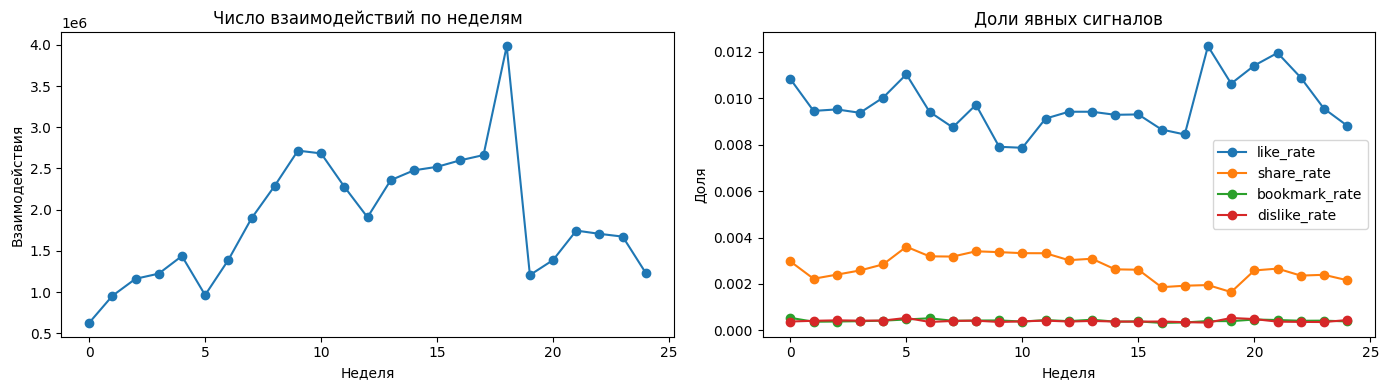

In [6]:
feedback_columns = ['like', 'dislike', 'share', 'bookmark', 'click_on_author', 'open_comments']

def summarize_split(lf, split):
    return lf.select(
        pl.lit(split).alias('split'),
        pl.len().alias('interactions'),
        pl.col('user_id').n_unique().alias('users'),
        pl.col('item_id').n_unique().alias('items'),
        pl.col('timespent').mean().alias('mean_timespent'),
        *[pl.col(c).sum().alias(c) for c in feedback_columns],
    ).collect(engine='streaming')

split_stats = pl.concat([
    summarize_split(train_lf, 'train'),
    summarize_split(validation_lf, 'validation'),
    summarize_split(test_lf, 'test'),
])
display(split_stats)

weekly_rows = []
for week, path in enumerate(tqdm(train_paths, desc='Статистика по неделям')):
    row = pl.scan_parquet(path).select(
        pl.lit(week).alias('week'),
        pl.len().alias('interactions'),
        pl.col('user_id').n_unique().alias('users'),
        pl.col('item_id').n_unique().alias('items'),
        *[pl.col(c).mean().alias(f'{c}_rate') for c in feedback_columns],
    ).collect(engine='streaming')
    weekly_rows.append(row)
weekly_stats = pl.concat(weekly_rows)
display(weekly_stats.head())

weekly_pd = weekly_stats.to_pandas()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(weekly_pd['week'], weekly_pd['interactions'], marker='o')
axes[0].set(title='Число взаимодействий по неделям', xlabel='Неделя', ylabel='Взаимодействия')
for column in ['like_rate', 'share_rate', 'bookmark_rate', 'dislike_rate']:
    axes[1].plot(weekly_pd['week'], weekly_pd[column], marker='o', label=column)
axes[1].set(title='Доли явных сигналов', xlabel='Неделя', ylabel='Доля')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'weekly_dynamics.png', dpi=150, bbox_inches='tight')
plt.show()


In [7]:
train_with_duration_lf = (
    train_lf.join(items_lf.select('item_id', 'duration'), on='item_id', how='left')
    .with_columns(
        pl.when(pl.col('duration') > 0)
        .then(pl.col('timespent').cast(pl.Float32) / pl.col('duration'))
        .otherwise(None).alias('watch_ratio')
    )
)
watch_stats = train_with_duration_lf.select(
    pl.len().alias('interactions'),
    pl.col('watch_ratio').mean().alias('mean_watch_ratio'),
    pl.col('watch_ratio').median().alias('median_watch_ratio'),
    *[(pl.col('watch_ratio') >= t).sum().alias(f'watched_{int(t*100)}pct') for t in (0.5, 0.7, 0.9, 1.0)],
).collect(engine='streaming')
display(watch_stats)

explicit_positive = pl.col('like') | pl.col('share') | pl.col('bookmark')
not_negative = ~pl.col('dislike')
threshold_comparison = train_with_duration_lf.select(
    pl.len().alias('all_interactions'),
    explicit_positive.sum().alias('explicit_positive'),
    *[(not_negative & (explicit_positive | (pl.col('watch_ratio') >= t))).sum()
      .alias(f'positive_at_{int(t*100)}pct') for t in (0.5, 0.7, 0.9)],
).collect(engine='streaming')
display(threshold_comparison)


interactions,mean_watch_ratio,median_watch_ratio,watched_50pct,watched_70pct,watched_90pct,watched_100pct
u32,f32,f32,u32,u32,u32,u32
47068641,0.469777,0.230769,17226836,13894830,10746187,9175617


all_interactions,explicit_positive,positive_at_50pct,positive_at_70pct,positive_at_90pct
u32,u32,u32,u32,u32
47068641,576367,17294983,14005071,10916920


In [8]:
quality_stats = train_lf.select(
    pl.len().alias('rows'),
    pl.struct(['user_id', 'item_id']).n_unique().alias('unique_user_item_pairs'),
    pl.col('user_id').null_count().alias('null_users'),
    pl.col('item_id').null_count().alias('null_items'),
).with_columns(
    (pl.col('rows') - pl.col('unique_user_item_pairs')).alias('duplicate_pairs')
).collect(engine='streaming')
display(quality_stats)


rows,unique_user_item_pairs,null_users,null_items,duplicate_pairs
u32,u32,u32,u32,u32
47068641,47068641,0,0,0


## 4. Матрицы взаимодействий и метрики

Положительные взаимодействия формируют обучающую матрицу, а вся история показов используется для исключения уже просмотренных объектов. Все модели оцениваются одинаково по `Recall@10`, `NDCG@10`, `MAP@10`, `HitRate@10` и `Coverage@10`.


In [9]:
from scipy.sparse import csr_matrix

WATCH_THRESHOLD = 0.70

def positive_interactions(interactions_lf):
    explicit = pl.col('like') | pl.col('share') | pl.col('bookmark')
    return (
        interactions_lf
        .join(items_lf.select('item_id', 'duration'), on='item_id', how='left')
        .with_columns(
            pl.when(pl.col('duration') > 0)
            .then(pl.col('timespent').cast(pl.Float32) / pl.col('duration'))
            .otherwise(0.0)
            .alias('watch_ratio')
        )
        .filter((~pl.col('dislike')) & (explicit | (pl.col('watch_ratio') >= WATCH_THRESHOLD)))
        .with_columns(
            (
                1.0
                + pl.col('watch_ratio').clip(0.0, 1.0)
                + 2.0 * pl.col('like').cast(pl.Float32)
                + 3.0 * pl.col('share').cast(pl.Float32)
                + 3.0 * pl.col('bookmark').cast(pl.Float32)
            ).cast(pl.Float32).alias('confidence')
        )
        .select('user_id', 'item_id', 'confidence')
    )

train_positive_df = positive_interactions(train_lf).collect(engine='streaming')
user_ids = np.sort(train_lf.select('user_id').unique().collect(engine='streaming')['user_id'].to_numpy())
item_ids = np.sort(train_lf.select('item_id').unique().collect(engine='streaming')['item_id'].to_numpy())

user_index = np.searchsorted(user_ids, train_positive_df['user_id'].to_numpy())
item_index = np.searchsorted(item_ids, train_positive_df['item_id'].to_numpy())
confidence = train_positive_df['confidence'].to_numpy().astype(np.float32)
train_matrix = csr_matrix(
    (confidence, (user_index, item_index)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32,
)
train_binary = train_matrix.copy()
train_binary.data[:] = 1.0

all_seen_df = train_lf.select('user_id', 'item_id').collect(engine='streaming')
seen_user_index = np.searchsorted(user_ids, all_seen_df['user_id'].to_numpy())
seen_item_index = np.searchsorted(item_ids, all_seen_df['item_id'].to_numpy())
seen_matrix = csr_matrix(
    (np.ones(len(all_seen_df), dtype=np.float32), (seen_user_index, seen_item_index)),
    shape=train_matrix.shape,
)
del all_seen_df, seen_user_index, seen_item_index, train_positive_df

print(f'Matrix shape: {train_matrix.shape}')
print(f'Positive interactions: {train_matrix.nnz:,}')
print(f'Positive density: {train_matrix.nnz / np.prod(train_matrix.shape):.4%}')
print(f'CSR memory: {(train_matrix.data.nbytes + train_matrix.indices.nbytes + train_matrix.indptr.nbytes) / 1024**2:.1f} MB')

def map_known(values, vocabulary):
    positions = np.searchsorted(vocabulary, values)
    valid = positions < len(vocabulary)
    valid[valid] &= vocabulary[positions[valid]] == values[valid]
    return positions, valid

def build_ground_truth(interactions_lf):
    positives = positive_interactions(interactions_lf).select('user_id', 'item_id').collect(engine='streaming')
    raw_users = positives['user_id'].to_numpy()
    raw_items = positives['item_id'].to_numpy()
    rows, known_users = map_known(raw_users, user_ids)
    cols, known_items = map_known(raw_items, item_ids)
    keep = known_users & known_items
    matrix = csr_matrix(
        (np.ones(keep.sum(), dtype=np.float32), (rows[keep], cols[keep])),
        shape=train_matrix.shape,
    )
    matrix.data[:] = 1.0
    return matrix

validation_ground_truth = build_ground_truth(validation_lf)
test_ground_truth = build_ground_truth(test_lf)

print(f'Validation positives on known users/items: {validation_ground_truth.nnz:,}')
print(f'Test positives on known users/items: {test_ground_truth.nnz:,}')
print(f'Validation users with positives: {np.count_nonzero(np.diff(validation_ground_truth.indptr)):,}')
print(f'Test users with positives: {np.count_nonzero(np.diff(test_ground_truth.indptr)):,}')


Matrix shape: (10000, 19628)
Positive interactions: 14,005,071
Positive density: 7.1353%
CSR memory: 106.9 MB


Validation positives on known users/items: 110,801
Test positives on known users/items: 82,496
Validation users with positives: 9,659
Test users with positives: 9,323


In [10]:
K = 10

def ranking_metrics(recommendations, evaluation_users, ground_truth, n_items, k=K):
    recalls, ndcgs, average_precisions, hits = [], [], [], []
    recommended_items = set()
    for row, user in enumerate(evaluation_users):
        relevant = ground_truth.indices[ground_truth.indptr[user]:ground_truth.indptr[user + 1]]
        predicted = recommendations[row, :k]
        is_hit = np.isin(predicted, relevant, assume_unique=False)
        hit_positions = np.flatnonzero(is_hit)
        hit_count = int(is_hit.sum())
        recalls.append(hit_count / len(relevant))
        hits.append(float(hit_count > 0))
        dcg = np.sum(1.0 / np.log2(hit_positions + 2.0))
        ideal = np.sum(1.0 / np.log2(np.arange(min(len(relevant), k)) + 2.0))
        ndcgs.append(dcg / ideal if ideal else 0.0)
        if hit_count:
            precision_at_hits = np.arange(1, hit_count + 1) / (hit_positions + 1)
            average_precisions.append(precision_at_hits.sum() / min(len(relevant), k))
        else:
            average_precisions.append(0.0)
        recommended_items.update(predicted[predicted >= 0].tolist())
    return {
        f'Recall@{k}': float(np.mean(recalls)),
        f'NDCG@{k}': float(np.mean(ndcgs)),
        f'MAP@{k}': float(np.mean(average_precisions)),
        f'HitRate@{k}': float(np.mean(hits)),
        f'Coverage@{k}': len(recommended_items) / n_items,
        'evaluated_users': len(evaluation_users),
    }

def users_with_ground_truth(matrix):
    return np.flatnonzero(np.diff(matrix.indptr) > 0)


## 5. Коллаборативные модели

`Popularity` служит неперсонализированной нижней границей. `ALS` моделирует взвешенную неявную уверенность, а `BPR` напрямую оптимизирует попарное ранжирование. Лучший коллаборативный алгоритм выбирается на валидации и затем оценивается на отложенной тестовой неделе.


In [11]:
item_popularity = np.asarray(train_binary.sum(axis=0)).ravel()
popular_order = np.argsort(-item_popularity)

def popularity_recommend(users, n=K):
    result = np.full((len(users), n), -1, dtype=np.int32)
    for row, user in enumerate(users):
        seen = seen_matrix.indices[seen_matrix.indptr[user]:seen_matrix.indptr[user + 1]]
        candidates = popular_order[~np.isin(popular_order, seen, assume_unique=False)]
        result[row] = candidates[:n]
    return result

validation_users = users_with_ground_truth(validation_ground_truth)
start = time.perf_counter()
popularity_validation_recs = popularity_recommend(validation_users)
popularity_time = time.perf_counter() - start
popularity_validation_metrics = ranking_metrics(
    popularity_validation_recs, validation_users, validation_ground_truth, len(item_ids)
)
popularity_validation_metrics['model'] = 'Popularity'
popularity_validation_metrics['train_time_sec'] = 0.0
popularity_validation_metrics['recommend_time_sec'] = popularity_time
display(pd.DataFrame([popularity_validation_metrics]).set_index('model'))


,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,train_time_sec,recommend_time_sec
model,,,,,,,,
Popularity,0.0,0.0,0.0,0.0,0.010648,9659,0.0,2.544098


In [12]:
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

models = {
    'ALS': AlternatingLeastSquares(
        factors=64, regularization=0.05, iterations=12,
        random_state=SEED, num_threads=0,
    ),
    'BPR': BayesianPersonalizedRanking(
        factors=64, learning_rate=0.05, regularization=0.01,
        iterations=20, random_state=SEED, num_threads=1,
        verify_negative_samples=True,
    ),
}

fit_times = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(train_matrix if name == 'ALS' else train_binary, show_progress=False)
    fit_times[name] = time.perf_counter() - start
    print(f'{name} training time: {fit_times[name]:.1f} sec')

def model_recommend(model, users, n=K, batch_size=512):
    batches = []
    for start_index in tqdm(range(0, len(users), batch_size), desc='Recommendation batches'):
        batch = users[start_index:start_index + batch_size]
        ids, _ = model.recommend(
            batch, seen_matrix[batch], N=n,
            filter_already_liked_items=True,
        )
        batches.append(ids.astype(np.int32))
    return np.vstack(batches)

validation_results = [popularity_validation_metrics]
for name, model in models.items():
    start = time.perf_counter()
    recommendations = model_recommend(model, validation_users)
    recommend_time = time.perf_counter() - start
    metrics = ranking_metrics(
        recommendations, validation_users, validation_ground_truth, len(item_ids)
    )
    metrics.update({
        'model': name,
        'train_time_sec': fit_times[name],
        'recommend_time_sec': recommend_time,
    })
    validation_results.append(metrics)

validation_results_df = pd.DataFrame(validation_results).set_index('model').sort_values(f'NDCG@{K}', ascending=False)
display(validation_results_df.style.format('{:.4f}'))
validation_results_df.to_csv(OUTPUT_DIR / 'cf_validation_metrics.csv')


ALS training time: 8.8 sec


BPR training time: 217.8 sec



Recommendation batches:   0%|          | 0/19 [00:00<?, ?it/s]


Recommendation batches:  11%|█         | 2/19 [00:00<00:01,  9.96it/s]


Recommendation batches:  16%|█▌        | 3/19 [00:00<00:01,  9.02it/s]

...


Recommendation batches:  74%|███████▎  | 14/19 [00:00<00:00, 14.50it/s]


Recommendation batches:  84%|████████▍ | 16/19 [00:01<00:00, 14.59it/s]


Recommendation batches:  95%|█████████▍| 18/19 [00:01<00:00, 14.95it/s]


Recommendation batches: 100%|██████████| 19/19 [00:01<00:00, 15.22it/s]

,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,train_time_sec,recommend_time_sec
model,,,,,,,,
BPR,0.0062,0.0076,0.0027,0.0613,0.7360,9659.0000,217.7670,1.2497
ALS,0.0031,0.0038,0.0013,0.0312,0.2651,9659.0000,8.8211,2.2280
Popularity,0.0000,0.0000,0.0000,0.0000,0.0106,9659.0000,0.0000,2.5441



Recommendation batches:   0%|          | 0/19 [00:00<?, ?it/s]


Recommendation batches:  11%|█         | 2/19 [00:00<00:01, 11.06it/s]


Recommendation batches:  21%|██        | 4/19 [00:00<00:01, 10.09it/s]


Recommendation batches:  32%|███▏      | 6/19 [00:00<00:01,  9.69it/s]


Recommendation batches:  37%|███▋      | 7/19 [00:00<00:01,  9.29it/s]

...


Recommendation batches:  74%|███████▎  | 14/19 [00:00<00:00, 15.71it/s]


Recommendation batches:  84%|████████▍ | 16/19 [00:01<00:00, 15.95it/s]


Recommendation batches:  95%|█████████▍| 18/19 [00:01<00:00, 16.03it/s]


Recommendation batches: 100%|██████████| 19/19 [00:01<00:00, 16.63it/s]

,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,recommend_time_sec
model,,,,,,,
BPR,0.0085,0.0080,0.0032,0.0553,0.7307,9323.0000,1.6622
ALS,0.0036,0.0035,0.0013,0.0255,0.2633,9323.0000,2.6678
Popularity,0.0000,0.0000,0.0000,0.0000,0.0106,9323.0000,2.4840


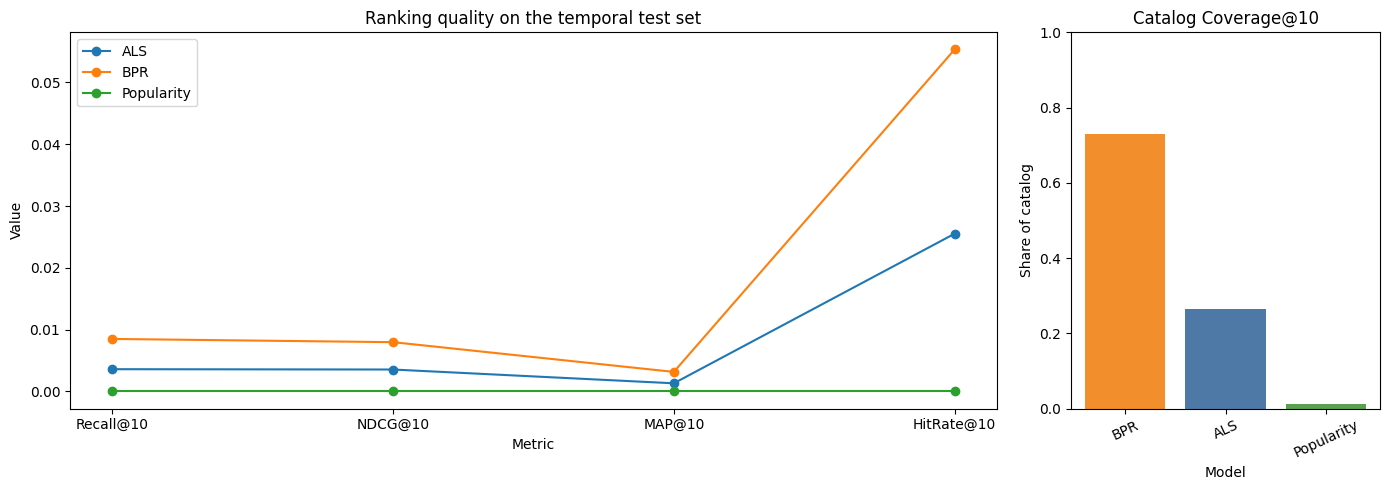

In [13]:
test_users = users_with_ground_truth(test_ground_truth)
test_results = []

start = time.perf_counter()
popularity_test_recs = popularity_recommend(test_users)
metrics = ranking_metrics(popularity_test_recs, test_users, test_ground_truth, len(item_ids))
metrics.update({'model': 'Popularity', 'recommend_time_sec': time.perf_counter() - start})
test_results.append(metrics)

for name, model in models.items():
    start = time.perf_counter()
    recommendations = model_recommend(model, test_users)
    metrics = ranking_metrics(recommendations, test_users, test_ground_truth, len(item_ids))
    metrics.update({'model': name, 'recommend_time_sec': time.perf_counter() - start})
    test_results.append(metrics)

test_results_df = pd.DataFrame(test_results).set_index('model').sort_values(f'NDCG@{K}', ascending=False)
display(test_results_df.style.format('{:.4f}'))
test_results_df.to_csv(OUTPUT_DIR / 'cf_test_metrics.csv')

ranking_columns = [f'Recall@{K}', f'NDCG@{K}', f'MAP@{K}', f'HitRate@{K}']
ranking_plot = test_results_df[ranking_columns].reset_index().melt(
    id_vars='model', var_name='metric', value_name='value'
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 1]})
for model_name, group in ranking_plot.groupby('model'):
    axes[0].plot(group['metric'], group['value'], marker='o', label=model_name)
axes[0].set(title='Ranking quality on the temporal test set', xlabel='Metric', ylabel='Value')
axes[0].legend()
coverage = test_results_df[f'Coverage@{K}'].sort_values(ascending=False)
axes[1].bar(coverage.index, coverage.values, color=['#f28e2b', '#4e79a7', '#59a14f'])
axes[1].set(title=f'Catalog Coverage@{K}', xlabel='Model', ylabel='Share of catalog', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cf_test_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Мультимодальные эмбеддинги и гибрид BPR + Content

VK-LSVD предоставляет единый 64-мерный `content-only` эмбеддинг, сформированный из видео, описания и аудио. Проверяются размерности 8/16/32/64. Контентный профиль пользователя строится как взвешенное среднее эмбеддингов, а позднее объединение нормализует оценки BPR и Content. Размерность и вес выбираются исключительно на валидации.


In [14]:
import gc

EMBEDDING_FILE = 'metadata/item_embeddings.npz'
embedding_path = Path(hf_hub_download(
    repo_id=REPO_ID,
    repo_type='dataset',
    filename=EMBEDDING_FILE,
    local_dir=DATA_DIR,
))
print(f'Embedding archive: {embedding_path}')
print(f'Archive size: {embedding_path.stat().st_size / 1024**3:.2f} GB')

filtered_embedding_path = OUTPUT_DIR / 'item_embeddings_subset.npy'

if filtered_embedding_path.exists():
    item_embeddings_64 = np.load(filtered_embedding_path)
else:
    with np.load(embedding_path) as archive:
        all_embedding_ids = archive['item_id']
        positions = np.searchsorted(all_embedding_ids, item_ids)
        if not np.all(positions < len(all_embedding_ids)) or not np.array_equal(all_embedding_ids[positions], item_ids):
            raise ValueError('Embedding item_id array is not sorted or does not cover the experiment catalog.')
        full_embeddings = archive['embedding']
        item_embeddings_64 = full_embeddings[positions].astype(np.float32)
    np.save(filtered_embedding_path, item_embeddings_64)
    del all_embedding_ids, full_embeddings
    gc.collect()

assert item_embeddings_64.shape == (len(item_ids), 64)
print(f'Filtered embedding shape: {item_embeddings_64.shape}')
print(f'Filtered embedding memory: {item_embeddings_64.nbytes / 1024**2:.1f} MB')


Embedding archive: data\VK-LSVD\metadata\item_embeddings.npz
Archive size: 2.20 GB
Filtered embedding shape: (19628, 64)
Filtered embedding memory: 4.8 MB


In [15]:
CONTENT_DIMS = [8, 16, 32, 64]
CANDIDATE_COUNT = 100
HYBRID_ALPHAS = [0.25, 0.50, 0.75]

def l2_normalize(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-12)

def content_representations(dimension):
    item_vectors = l2_normalize(item_embeddings_64[:, :dimension].astype(np.float32))
    user_vectors = train_matrix @ item_vectors
    user_vectors = l2_normalize(np.asarray(user_vectors, dtype=np.float32))
    return user_vectors, item_vectors

def content_recommend(user_vectors, item_vectors, users, n=CANDIDATE_COUNT, batch_size=256):
    recommendations = np.empty((len(users), n), dtype=np.int32)
    for offset in tqdm(range(0, len(users), batch_size), desc='Content retrieval'):
        batch_users = users[offset:offset + batch_size]
        scores = user_vectors[batch_users] @ item_vectors.T
        for row, user in enumerate(batch_users):
            seen = seen_matrix.indices[seen_matrix.indptr[user]:seen_matrix.indptr[user + 1]]
            scores[row, seen] = -np.inf
        top = np.argpartition(scores, -n, axis=1)[:, -n:]
        top_scores = np.take_along_axis(scores, top, axis=1)
        order = np.argsort(-top_scores, axis=1)
        recommendations[offset:offset + len(batch_users)] = np.take_along_axis(top, order, axis=1)
    return recommendations


In [16]:
def bpr_recommend_with_scores(users, n=CANDIDATE_COUNT, batch_size=512):
    all_ids, all_scores = [], []
    model = models['BPR']
    for offset in tqdm(range(0, len(users), batch_size), desc='BPR candidates'):
        batch = users[offset:offset + batch_size]
        ids, scores = model.recommend(
            batch, seen_matrix[batch], N=n,
            filter_already_liked_items=True,
        )
        all_ids.append(ids.astype(np.int32))
        all_scores.append(scores.astype(np.float32))
    return np.vstack(all_ids), np.vstack(all_scores)

def minmax(values):
    low, high = values.min(), values.max()
    return (values - low) / max(high - low, 1e-12)

def hybrid_rerank(users, bpr_candidates, content_candidates, user_vectors, item_vectors, alpha, n=K):
    model = models['BPR']
    result = np.empty((len(users), n), dtype=np.int32)
    for row, user in enumerate(users):
        candidates = np.unique(np.concatenate([bpr_candidates[row], content_candidates[row]]))
        collaborative_scores = model.item_factors[candidates] @ model.user_factors[user]
        content_scores = item_vectors[candidates] @ user_vectors[user]
        fused = alpha * minmax(collaborative_scores) + (1.0 - alpha) * minmax(content_scores)
        best = np.argpartition(fused, -n)[-n:]
        best = best[np.argsort(-fused[best])]
        result[row] = candidates[best]
    return result

validation_bpr_candidates, _ = bpr_recommend_with_scores(validation_users)

hybrid_validation_rows = []
content_cache = {}

for dimension in CONTENT_DIMS:
    print(f'\nEvaluating content dimension {dimension}')
    user_vectors, item_vectors = content_representations(dimension)
    content_candidates = content_recommend(user_vectors, item_vectors, validation_users)
    content_cache[dimension] = (user_vectors, item_vectors)

    content_metrics = ranking_metrics(
        content_candidates[:, :K], validation_users, validation_ground_truth, len(item_ids)
    )
    content_metrics.update({'model': f'Content-{dimension}', 'dimension': dimension, 'alpha': 0.0})
    hybrid_validation_rows.append(content_metrics)

    for alpha in HYBRID_ALPHAS:
        recommendations = hybrid_rerank(
            validation_users, validation_bpr_candidates, content_candidates,
            user_vectors, item_vectors, alpha,
        )
        metrics = ranking_metrics(
            recommendations, validation_users, validation_ground_truth, len(item_ids)
        )
        metrics.update({
            'model': f'Hybrid-{dimension}-a{alpha:.2f}',
            'dimension': dimension,
            'alpha': alpha,
        })
        hybrid_validation_rows.append(metrics)

hybrid_validation_df = pd.DataFrame(hybrid_validation_rows).set_index('model')
hybrid_validation_df = hybrid_validation_df.sort_values(f'NDCG@{K}', ascending=False)
display(hybrid_validation_df.style.format('{:.4f}'))
hybrid_validation_df.to_csv(OUTPUT_DIR / 'hybrid_validation_metrics.csv')

hybrid_only = hybrid_validation_df[hybrid_validation_df['alpha'] > 0]
best_hybrid_name = hybrid_only[f'NDCG@{K}'].idxmax()
best_dimension = int(hybrid_only.loc[best_hybrid_name, 'dimension'])
best_alpha = float(hybrid_only.loc[best_hybrid_name, 'alpha'])

print(f'Best validation hybrid: {best_hybrid_name}')
print(f'Dimension: {best_dimension}; BPR alpha: {best_alpha:.2f}')
print(f'Validation NDCG@{K}: {hybrid_only.loc[best_hybrid_name, f"NDCG@{K}"]:.6f}')



BPR candidates:   0%|          | 0/19 [00:00<?, ?it/s]


BPR candidates:  11%|█         | 2/19 [00:00<00:01, 12.26it/s]


BPR candidates:  21%|██        | 4/19 [00:00<00:01, 12.52it/s]


BPR candidates:  32%|███▏      | 6/19 [00:00<00:01, 12.78it/s]


BPR candidates:  42%|████▏     | 8/19 [00:00<00:00, 12.85it/s]

...


Content retrieval:  95%|█████████▍| 36/38 [00:02<00:00, 16.27it/s]


Content retrieval: 100%|██████████| 38/38 [00:02<00:00, 17.10it/s]


Content retrieval: 100%|██████████| 38/38 [00:02<00:00, 15.57it/s]

,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,dimension,alpha
model,,,,,,,,
Hybrid-8-a0.75,0.0062,0.0077,0.0028,0.0600,0.6162,9659.0000,8.0000,0.7500
Hybrid-16-a0.75,0.0062,0.0076,0.0028,0.0598,0.5990,9659.0000,16.0000,0.7500
Hybrid-32-a0.75,0.0063,0.0075,0.0027,0.0594,0.5820,9659.0000,32.0000,0.7500
Hybrid-64-a0.75,0.0061,0.0074,0.0027,0.0593,0.5705,9659.0000,64.0000,0.7500
Hybrid-8-a0.50,0.0055,0.0071,0.0026,0.0540,0.3862,9659.0000,8.0000,0.5000
Hybrid-16-a0.50,0.0059,0.0069,0.0025,0.0553,0.3470,9659.0000,16.0000,0.5000
Hybrid-32-a0.50,0.0050,0.0063,0.0023,0.0503,0.3194,9659.0000,32.0000,0.5000
Hybrid-64-a0.50,0.0050,0.0063,0.0023,0.0505,0.2971,9659.0000,64.0000,0.5000
Hybrid-8-a0.25,0.0042,0.0056,0.0021,0.0420,0.1651,9659.0000,8.0000,0.2500


Best validation hybrid: Hybrid-8-a0.75
Dimension: 8; BPR alpha: 0.75
Validation NDCG@10: 0.007662



Content retrieval:   0%|          | 0/37 [00:00<?, ?it/s]


Content retrieval:  11%|█         | 4/37 [00:00<00:01, 30.39it/s]


Content retrieval:  22%|██▏       | 8/37 [00:00<00:00, 31.22it/s]


Content retrieval:  32%|███▏      | 12/37 [00:00<00:00, 30.95it/s]


Content retrieval:  43%|████▎     | 16/37 [00:00<00:00, 31.06it/s]

...


BPR candidates:  74%|███████▎  | 14/19 [00:01<00:00, 13.70it/s]


BPR candidates:  84%|████████▍ | 16/19 [00:01<00:00, 13.83it/s]


BPR candidates:  95%|█████████▍| 18/19 [00:01<00:00, 13.60it/s]


BPR candidates: 100%|██████████| 19/19 [00:01<00:00, 14.23it/s]

,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,recommend_time_sec
model,,,,,,,
BPR,0.0085,0.0080,0.0032,0.0553,0.7307,9323.0000,1.6622
Content-8,0.0005,0.0006,0.0002,0.0053,0.0354,9323.0000,nan
Hybrid-8-a0.75,0.0079,0.0077,0.0031,0.0531,0.6112,9323.0000,nan


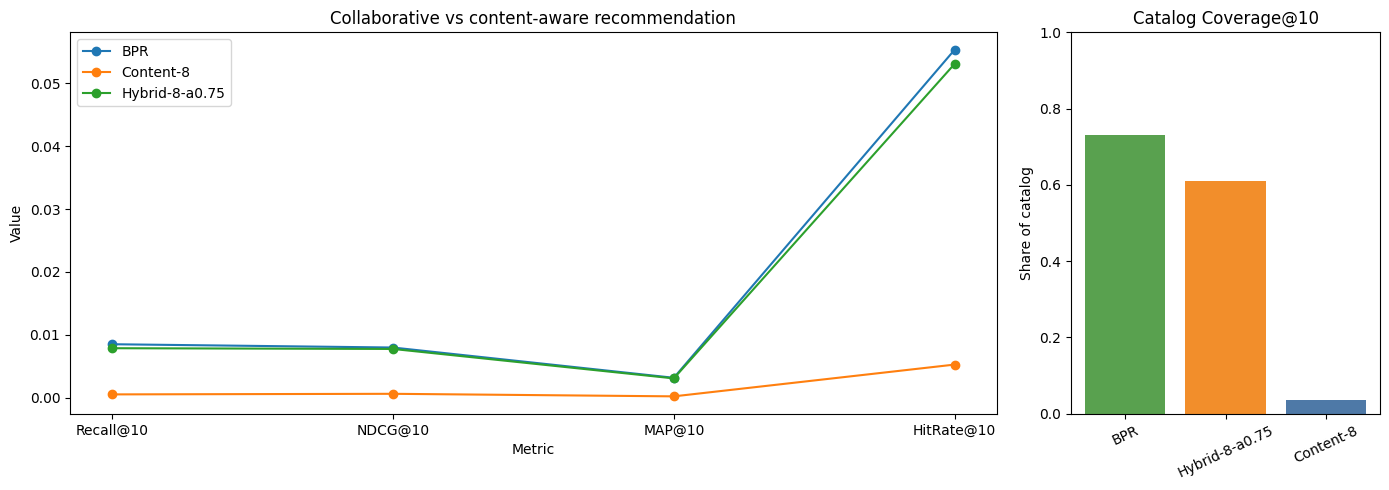

In [17]:
best_user_vectors, best_item_vectors = content_cache[best_dimension]
test_content_candidates = content_recommend(best_user_vectors, best_item_vectors, test_users)
test_bpr_candidates, _ = bpr_recommend_with_scores(test_users)
test_hybrid_recommendations = hybrid_rerank(
    test_users, test_bpr_candidates, test_content_candidates,
    best_user_vectors, best_item_vectors, best_alpha,
)

content_test_metrics = ranking_metrics(
    test_content_candidates[:, :K], test_users, test_ground_truth, len(item_ids)
)
hybrid_test_metrics = ranking_metrics(
    test_hybrid_recommendations, test_users, test_ground_truth, len(item_ids)
)

final_comparison = pd.DataFrame([
    {'model': 'BPR', **test_results_df.loc['BPR'].to_dict()},
    {'model': f'Content-{best_dimension}', **content_test_metrics},
    {'model': f'Hybrid-{best_dimension}-a{best_alpha:.2f}', **hybrid_test_metrics},
]).set_index('model')
display(final_comparison.style.format('{:.4f}'))
final_comparison.to_csv(OUTPUT_DIR / 'hybrid_test_metrics.csv')

ranking_columns = [f'Recall@{K}', f'NDCG@{K}', f'MAP@{K}', f'HitRate@{K}']
plot_data = final_comparison[ranking_columns].reset_index().melt(
    id_vars='model', var_name='metric', value_name='value'
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 1]})
for model_name, group in plot_data.groupby('model'):
    axes[0].plot(group['metric'], group['value'], marker='o', label=model_name)
axes[0].set(title='Collaborative vs content-aware recommendation', xlabel='Metric', ylabel='Value')
axes[0].legend()
coverage = final_comparison[f'Coverage@{K}'].sort_values(ascending=False)
axes[1].bar(coverage.index, coverage.values, color=['#59a14f', '#f28e2b', '#4e79a7'])
axes[1].set(title=f'Catalog Coverage@{K}', ylabel='Share of catalog', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'hybrid_test_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Метаданные и объединённая модель

В качестве интерпретируемых контентных сигналов используются предпочтение автора и близость длительности ролика к истории пользователя. Сравниваются Metadata-only, BPR + Metadata и BPR + Content + Metadata. Все веса снова определяются только по валидации, после чего выбранные конфигурации оцениваются на тесте.


In [18]:
catalog_metadata = (
    pl.DataFrame({'item_id': item_ids}).lazy()
    .join(items_lf.select('item_id', 'author_id', 'duration'), on='item_id', how='left')
    .collect()
)
assert catalog_metadata.height == len(item_ids)
has_missing_metadata = catalog_metadata.select(
    pl.any_horizontal(pl.all().is_null()).any().alias('has_missing')
).item()
assert not has_missing_metadata

author_ids, item_author_codes = np.unique(
    catalog_metadata['author_id'].to_numpy(), return_inverse=True
)
item_durations = catalog_metadata['duration'].to_numpy().astype(np.float32)
duration_scale = max(float(np.std(item_durations)), 1.0)

item_author_matrix = csr_matrix(
    (np.ones(len(item_ids), dtype=np.float32), (np.arange(len(item_ids)), item_author_codes)),
    shape=(len(item_ids), len(author_ids)),
)
user_author_preferences = (train_matrix @ item_author_matrix).tocsr()
author_row_max = np.asarray(user_author_preferences.max(axis=1).toarray()).ravel()
author_row_max = np.maximum(author_row_max, 1e-12)

user_weight = np.asarray(train_matrix.sum(axis=1)).ravel()
user_mean_duration = np.asarray(train_matrix @ item_durations).ravel() / np.maximum(user_weight, 1e-12)

print(f'Catalog items: {len(item_ids):,}')
print(f'Unique authors: {len(author_ids):,}')
print(f'Duration mean/std: {item_durations.mean():.1f}/{item_durations.std():.1f} sec')

def metadata_score_matrix(users):
    author_scores = user_author_preferences[users][:, item_author_codes].toarray()
    author_scores /= author_row_max[users, None]
    duration_scores = np.exp(
        -np.abs(user_mean_duration[users, None] - item_durations[None, :]) / duration_scale
    )
    return 0.7 * author_scores + 0.3 * duration_scores

def metadata_recommend(users, n=CANDIDATE_COUNT, batch_size=256):
    recommendations = np.empty((len(users), n), dtype=np.int32)
    for offset in tqdm(range(0, len(users), batch_size), desc='Metadata retrieval'):
        batch_users = users[offset:offset + batch_size]
        scores = metadata_score_matrix(batch_users)
        for row, user in enumerate(batch_users):
            seen = seen_matrix.indices[seen_matrix.indptr[user]:seen_matrix.indptr[user + 1]]
            scores[row, seen] = -np.inf
        top = np.argpartition(scores, -n, axis=1)[:, -n:]
        top_scores = np.take_along_axis(scores, top, axis=1)
        order = np.argsort(-top_scores, axis=1)
        recommendations[offset:offset + len(batch_users)] = np.take_along_axis(top, order, axis=1)
    return recommendations

def metadata_scores_for_candidates(user, candidates):
    author = user_author_preferences[user, item_author_codes[candidates]].toarray().ravel()
    author = author / author_row_max[user]
    duration = np.exp(-np.abs(user_mean_duration[user] - item_durations[candidates]) / duration_scale)
    return 0.7 * author + 0.3 * duration


Catalog items: 19,628
Unique authors: 4,942
Duration mean/std: 47.1/36.2 sec


In [19]:
validation_metadata_candidates = metadata_recommend(validation_users)
metadata_validation_metrics = ranking_metrics(
    validation_metadata_candidates[:, :K], validation_users,
    validation_ground_truth, len(item_ids),
)

def metadata_hybrid_rerank(users, bpr_candidates, metadata_candidates, alpha, n=K):
    model = models['BPR']
    result = np.empty((len(users), n), dtype=np.int32)
    for row, user in enumerate(users):
        candidates = np.unique(np.concatenate([bpr_candidates[row], metadata_candidates[row]]))
        collaborative = model.item_factors[candidates] @ model.user_factors[user]
        metadata = metadata_scores_for_candidates(user, candidates)
        fused = alpha * minmax(collaborative) + (1.0 - alpha) * minmax(metadata)
        best = np.argpartition(fused, -n)[-n:]
        best = best[np.argsort(-fused[best])]
        result[row] = candidates[best]
    return result

metadata_validation_rows = [
    {'model': 'Metadata-only', 'alpha': 0.0, **metadata_validation_metrics}
]
for alpha in HYBRID_ALPHAS:
    recommendations = metadata_hybrid_rerank(
        validation_users, validation_bpr_candidates,
        validation_metadata_candidates, alpha,
    )
    metrics = ranking_metrics(
        recommendations, validation_users, validation_ground_truth, len(item_ids)
    )
    metadata_validation_rows.append({
        'model': f'BPR-Metadata-a{alpha:.2f}', 'alpha': alpha, **metrics
    })

metadata_validation_df = pd.DataFrame(metadata_validation_rows).set_index('model')
metadata_validation_df = metadata_validation_df.sort_values(f'NDCG@{K}', ascending=False)
display(metadata_validation_df.style.format('{:.4f}'))
metadata_validation_df.to_csv(OUTPUT_DIR / 'metadata_validation_metrics.csv')

best_content_user_vectors, best_content_item_vectors = content_cache[best_dimension]
validation_best_content_candidates = content_recommend(
    best_content_user_vectors, best_content_item_vectors, validation_users
)

def combined_rerank(
    users, bpr_candidates, content_candidates, metadata_candidates,
    user_vectors, item_vectors, bpr_alpha, content_share, n=K,
):
    model = models['BPR']
    result = np.empty((len(users), n), dtype=np.int32)
    for row, user in enumerate(users):
        candidates = np.unique(np.concatenate([
            bpr_candidates[row], content_candidates[row], metadata_candidates[row]
        ]))
        collaborative = model.item_factors[candidates] @ model.user_factors[user]
        content = item_vectors[candidates] @ user_vectors[user]
        metadata = metadata_scores_for_candidates(user, candidates)
        content_mix = content_share * minmax(content) + (1.0 - content_share) * minmax(metadata)
        fused = bpr_alpha * minmax(collaborative) + (1.0 - bpr_alpha) * content_mix
        best = np.argpartition(fused, -n)[-n:]
        best = best[np.argsort(-fused[best])]
        result[row] = candidates[best]
    return result

combined_validation_rows = []
for bpr_alpha in (0.50, 0.75):
    for content_share in (0.25, 0.50, 0.75):
        recommendations = combined_rerank(
            validation_users, validation_bpr_candidates,
            validation_best_content_candidates, validation_metadata_candidates,
            best_content_user_vectors, best_content_item_vectors,
            bpr_alpha, content_share,
        )
        metrics = ranking_metrics(
            recommendations, validation_users, validation_ground_truth, len(item_ids)
        )
        combined_validation_rows.append({
            'model': f'Combined-b{bpr_alpha:.2f}-c{content_share:.2f}',
            'bpr_alpha': bpr_alpha,
            'content_share': content_share,
            **metrics,
        })

combined_validation_df = pd.DataFrame(combined_validation_rows).set_index('model')
combined_validation_df = combined_validation_df.sort_values(f'NDCG@{K}', ascending=False)
display(combined_validation_df.style.format('{:.4f}'))
combined_validation_df.to_csv(OUTPUT_DIR / 'combined_validation_metrics.csv')

best_metadata_hybrid = metadata_validation_df[metadata_validation_df['alpha'] > 0]
best_metadata_name = best_metadata_hybrid[f'NDCG@{K}'].idxmax()
best_metadata_alpha = float(best_metadata_hybrid.loc[best_metadata_name, 'alpha'])

best_combined_name = combined_validation_df[f'NDCG@{K}'].idxmax()
best_bpr_alpha = float(combined_validation_df.loc[best_combined_name, 'bpr_alpha'])
best_content_share = float(combined_validation_df.loc[best_combined_name, 'content_share'])

print(f'Best metadata hybrid: {best_metadata_name}')
print(f'Best combined model: {best_combined_name}')



Metadata retrieval:   0%|          | 0/38 [00:00<?, ?it/s]


Metadata retrieval:   3%|▎         | 1/38 [00:00<00:04,  8.74it/s]


Metadata retrieval:   5%|▌         | 2/38 [00:00<00:04,  8.58it/s]


Metadata retrieval:   8%|▊         | 3/38 [00:00<00:04,  8.30it/s]


Metadata retrieval:  11%|█         | 4/38 [00:00<00:04,  8.37it/s]

...


Content retrieval:  84%|████████▍ | 32/38 [00:01<00:00, 30.01it/s]


Content retrieval:  95%|█████████▍| 36/38 [00:01<00:00, 30.61it/s]


Content retrieval: 100%|██████████| 38/38 [00:01<00:00, 30.48it/s]

,bpr_alpha,content_share,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users
model,,,,,,,,
Combined-b0.75-c0.75,0.7500,0.7500,0.0063,0.0074,0.0027,0.0594,0.6645,9659.0000
Combined-b0.75-c0.50,0.7500,0.5000,0.0053,0.0063,0.0022,0.0519,0.6833,9659.0000
Combined-b0.50-c0.75,0.5000,0.7500,0.0045,0.0054,0.0019,0.0441,0.4409,9659.0000
Combined-b0.75-c0.25,0.7500,0.2500,0.0043,0.0048,0.0016,0.0411,0.6650,9659.0000
Combined-b0.50-c0.50,0.5000,0.5000,0.0019,0.0021,0.0007,0.0179,0.3452,9659.0000
Combined-b0.50-c0.25,0.5000,0.2500,0.0007,0.0007,0.0003,0.0056,0.1857,9659.0000


Best metadata hybrid: BPR-Metadata-a0.75
Best combined model: Combined-b0.75-c0.75



Metadata retrieval:   0%|          | 0/37 [00:00<?, ?it/s]


Metadata retrieval:   3%|▎         | 1/37 [00:00<00:06,  5.47it/s]


Metadata retrieval:   5%|▌         | 2/37 [00:00<00:05,  5.98it/s]


Metadata retrieval:   8%|▊         | 3/37 [00:00<00:05,  6.77it/s]


Metadata retrieval:  11%|█         | 4/37 [00:00<00:04,  7.10it/s]

...


Metadata retrieval:  92%|█████████▏| 34/37 [00:04<00:00,  8.18it/s]


Metadata retrieval:  95%|█████████▍| 35/37 [00:04<00:00,  7.81it/s]


Metadata retrieval:  97%|█████████▋| 36/37 [00:04<00:00,  7.87it/s]


Metadata retrieval: 100%|██████████| 37/37 [00:04<00:00,  8.36it/s]

,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,recommend_time_sec
model,,,,,,,
BPR,0.0085,0.0080,0.0032,0.0553,0.7307,9323.0000,1.6622
BPR-Content-8,0.0079,0.0077,0.0031,0.0531,0.6112,9323.0000,nan
BPR-Content-Metadata,0.0075,0.0074,0.0030,0.0507,0.6597,9323.0000,nan
BPR-Metadata-a0.75,0.0054,0.0051,0.0019,0.0370,0.6593,9323.0000,nan
Content-8,0.0005,0.0006,0.0002,0.0053,0.0354,9323.0000,nan
Metadata-only,0.0002,0.0002,0.0001,0.0012,0.0866,9323.0000,nan


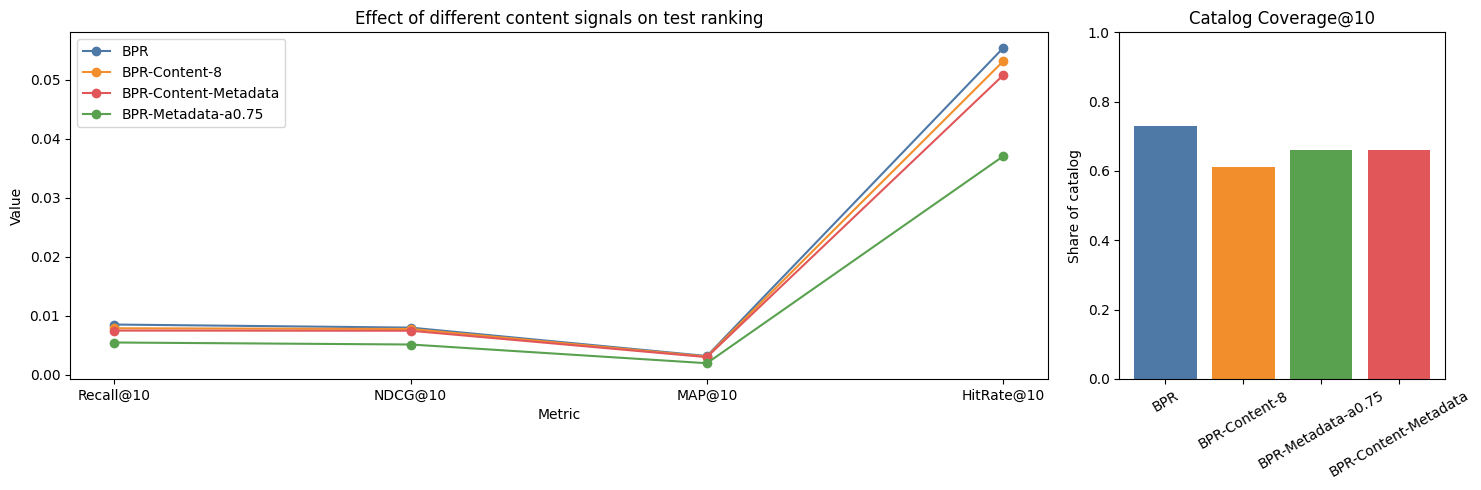

In [20]:
test_metadata_candidates = metadata_recommend(test_users)

metadata_test_metrics = ranking_metrics(
    test_metadata_candidates[:, :K], test_users, test_ground_truth, len(item_ids)
)
metadata_hybrid_test_recs = metadata_hybrid_rerank(
    test_users, test_bpr_candidates, test_metadata_candidates, best_metadata_alpha,
)
metadata_hybrid_test_metrics = ranking_metrics(
    metadata_hybrid_test_recs, test_users, test_ground_truth, len(item_ids)
)

combined_test_recs = combined_rerank(
    test_users, test_bpr_candidates, test_content_candidates, test_metadata_candidates,
    best_content_user_vectors, best_content_item_vectors,
    best_bpr_alpha, best_content_share,
)
combined_test_metrics = ranking_metrics(
    combined_test_recs, test_users, test_ground_truth, len(item_ids)
)

all_content_test_results = pd.DataFrame([
    {'model': 'BPR', **test_results_df.loc['BPR'].to_dict()},
    {'model': f'Content-{best_dimension}', **content_test_metrics},
    {'model': f'BPR-Content-{best_dimension}', **hybrid_test_metrics},
    {'model': 'Metadata-only', **metadata_test_metrics},
    {'model': f'BPR-Metadata-a{best_metadata_alpha:.2f}', **metadata_hybrid_test_metrics},
    {'model': 'BPR-Content-Metadata', **combined_test_metrics},
]).set_index('model').sort_values(f'NDCG@{K}', ascending=False)

display(all_content_test_results.style.format('{:.4f}'))
all_content_test_results.to_csv(OUTPUT_DIR / 'all_content_test_metrics.csv')

ranking_columns = [f'Recall@{K}', f'NDCG@{K}', f'MAP@{K}', f'HitRate@{K}']
plot_models = ['BPR', f'BPR-Content-{best_dimension}', f'BPR-Metadata-a{best_metadata_alpha:.2f}', 'BPR-Content-Metadata']
plot_frame = all_content_test_results.loc[plot_models]
plot_data = plot_frame[ranking_columns].reset_index().melt(
    id_vars='model', var_name='metric', value_name='value'
)
palette = dict(zip(plot_models, ['#4e79a7', '#f28e2b', '#59a14f', '#e15759']))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 1]})
for model_name, group in plot_data.groupby('model'):
    axes[0].plot(group['metric'], group['value'], marker='o', label=model_name, color=palette[model_name])
axes[0].set(title='Effect of different content signals on test ranking', xlabel='Metric', ylabel='Value')
axes[0].legend()
coverage = plot_frame[f'Coverage@{K}']
axes[1].bar(coverage.index, coverage.values, color=[palette[name] for name in coverage.index])
axes[1].set(title=f'Catalog Coverage@{K}', ylabel='Share of catalog', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'all_content_test_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Анализ по активности пользователей и популярности объектов

Качество сравнивается по квартилям активности пользователей и по популярности объектов. В выбранном поднаборе нет объектов с нулём положительных обучающих взаимодействий, поэтому настоящий item cold-start оценить нельзя; сегмент `Tail` используется только как приближение к редким объектам.


In [21]:
test_bpr_recommendations = test_bpr_candidates[:, :K]
test_model_recommendations = {
    'BPR': test_bpr_recommendations,
    f'BPR-Content-{best_dimension}': test_hybrid_recommendations,
    'BPR-Content-Metadata': combined_test_recs,
}

user_positive_activity = np.diff(train_binary.indptr)
activity_edges = np.quantile(user_positive_activity[test_users], [0.25, 0.50, 0.75])
activity_labels = ['Q1-low', 'Q2', 'Q3', 'Q4-high']
activity_bucket = np.digitize(user_positive_activity[test_users], activity_edges, right=True)

user_segment_rows = []
for bucket, label in enumerate(activity_labels):
    positions = np.flatnonzero(activity_bucket == bucket)
    segment_users = test_users[positions]
    for model_name, recommendations in test_model_recommendations.items():
        metrics = ranking_metrics(
            recommendations[positions], segment_users, test_ground_truth, len(item_ids)
        )
        user_segment_rows.append({
            'segment': label,
            'model': model_name,
            'activity_min': int(user_positive_activity[segment_users].min()),
            'activity_max': int(user_positive_activity[segment_users].max()),
            **metrics,
        })

user_segment_df = pd.DataFrame(user_segment_rows)
display(user_segment_df.set_index(['segment', 'model']).style.format('{:.4f}'))
user_segment_df.to_csv(OUTPUT_DIR / 'user_activity_segments.csv', index=False)


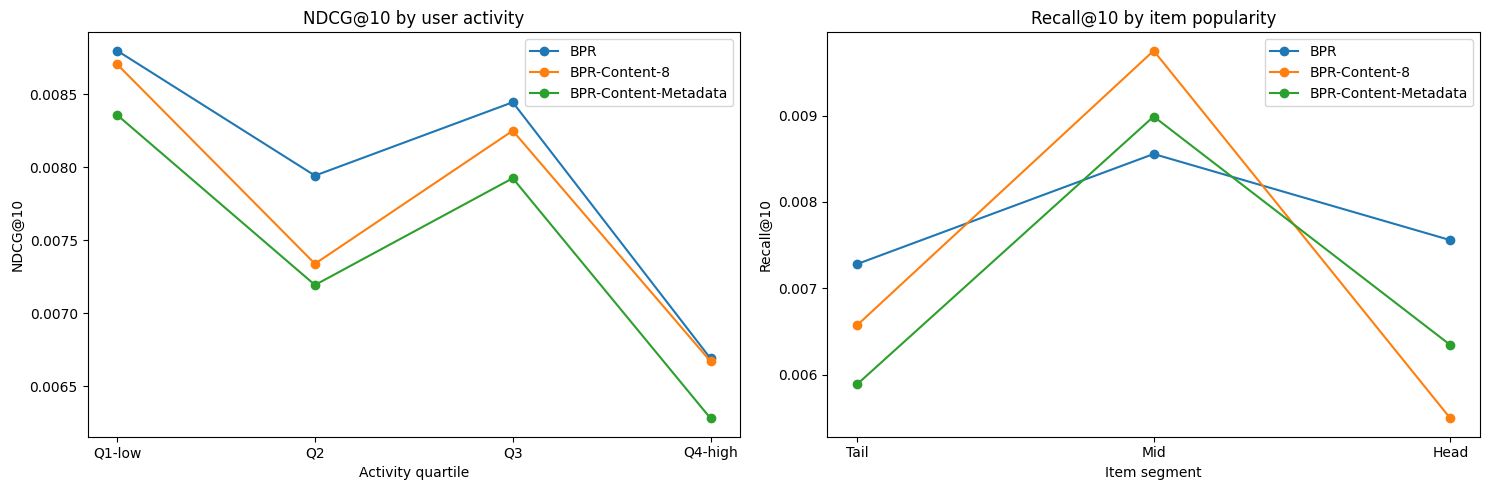

In [22]:
item_positive_popularity = np.asarray(train_binary.sum(axis=0)).ravel()
nonzero_popularity = item_positive_popularity[item_positive_popularity > 0]
tail_threshold = np.quantile(nonzero_popularity, 0.50)
head_threshold = np.quantile(nonzero_popularity, 0.80)

item_segment_masks = {
    'Cold-zero': item_positive_popularity == 0,
    'Tail': (item_positive_popularity > 0) & (item_positive_popularity <= tail_threshold),
    'Mid': (item_positive_popularity > tail_threshold) & (item_positive_popularity < head_threshold),
    'Head': item_positive_popularity >= head_threshold,
}

def ground_truth_for_items(ground_truth, item_mask):
    filtered = ground_truth.copy()
    keep = item_mask[filtered.indices]
    filtered.data[~keep] = 0.0
    filtered.eliminate_zeros()
    return filtered

item_segment_rows = []
for segment, item_mask in item_segment_masks.items():
    if not item_mask.any():
        continue
    segment_ground_truth = ground_truth_for_items(test_ground_truth, item_mask)
    segment_users = users_with_ground_truth(segment_ground_truth)
    user_positions = np.searchsorted(test_users, segment_users)
    for model_name, recommendations in test_model_recommendations.items():
        metrics = ranking_metrics(
            recommendations[user_positions], segment_users,
            segment_ground_truth, len(item_ids),
        )
        item_segment_rows.append({
            'segment': segment,
            'model': model_name,
            'catalog_items': int(item_mask.sum()),
            'test_positives': int(segment_ground_truth.nnz),
            **metrics,
        })

item_segment_df = pd.DataFrame(item_segment_rows)
display(item_segment_df.set_index(['segment', 'model']).style.format('{:.4f}'))
item_segment_df.to_csv(OUTPUT_DIR / 'item_popularity_segments.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for model_name, group in user_segment_df.groupby('model'):
    ordered = group.set_index('segment').loc[activity_labels]
    axes[0].plot(ordered.index, ordered[f'NDCG@{K}'], marker='o', label=model_name)
axes[0].set(title=f'NDCG@{K} by user activity', xlabel='Activity quartile', ylabel=f'NDCG@{K}')
axes[0].legend()

segment_order = ['Tail', 'Mid', 'Head']
for model_name, group in item_segment_df.groupby('model'):
    ordered = group.set_index('segment').loc[segment_order]
    axes[1].plot(ordered.index, ordered[f'Recall@{K}'], marker='o', label=model_name)
axes[1].set(title=f'Recall@{K} by item popularity', xlabel='Item segment', ylabel=f'Recall@{K}')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'segment_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Устойчивость результатов

BPR переобучается с тремя random seed в однопоточном режиме. Отдельно удаляются 10% и 20% положительных обучающих взаимодействий при неизменной истории показов. Это измеряет чувствительность ранжирования к инициализации и потере информации.


In [23]:
STABILITY_SEEDS = [7, 42, 2026]

def recommend_external_model(model, users, n=K, batch_size=512):
    batches = []
    for offset in range(0, len(users), batch_size):
        batch = users[offset:offset + batch_size]
        ids, _ = model.recommend(
            batch, seen_matrix[batch], N=n,
            filter_already_liked_items=True,
        )
        batches.append(ids.astype(np.int32))
    return np.vstack(batches)

seed_stability_rows = []
for seed in tqdm(STABILITY_SEEDS, desc='BPR seeds'):
    stable_model = BayesianPersonalizedRanking(
        factors=64, learning_rate=0.05, regularization=0.01,
        iterations=20, random_state=seed, num_threads=1,
        verify_negative_samples=True,
    )
    start = time.perf_counter()
    stable_model.fit(train_binary, show_progress=False)
    train_seconds = time.perf_counter() - start
    recommendations = recommend_external_model(stable_model, test_users)
    metrics = ranking_metrics(
        recommendations, test_users, test_ground_truth, len(item_ids)
    )
    seed_stability_rows.append({'seed': seed, 'train_time_sec': train_seconds, **metrics})
    del stable_model, recommendations
    gc.collect()

seed_stability_df = pd.DataFrame(seed_stability_rows)
display(seed_stability_df.style.format('{:.6f}'))
seed_stability_df.to_csv(OUTPUT_DIR / 'seed_stability_runs.csv', index=False)

stability_metric_columns = [
    f'Recall@{K}', f'NDCG@{K}', f'MAP@{K}', f'HitRate@{K}', f'Coverage@{K}'
]
seed_stability_summary = seed_stability_df[stability_metric_columns].agg(['mean', 'std']).T
seed_stability_summary['coefficient_of_variation'] = (
    seed_stability_summary['std'] / seed_stability_summary['mean'].replace(0, np.nan)
)
display(seed_stability_summary.style.format('{:.6f}'))
seed_stability_summary.to_csv(OUTPUT_DIR / 'seed_stability_summary.csv')



BPR seeds:   0%|          | 0/3 [00:00<?, ?it/s]


BPR seeds:  33%|███▎      | 1/3 [03:25<06:50, 205.22s/it]


BPR seeds:  67%|██████▋   | 2/3 [06:51<03:25, 205.86s/it]


BPR seeds: 100%|██████████| 3/3 [10:17<00:00, 205.75s/it]


BPR seeds: 100%|██████████| 3/3 [10:17<00:00, 205.72s/it]

,seed,train_time_sec,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users
0,7.000000,202.782241,0.006623,0.007017,0.002850,0.049233,0.737263,9323.000000
1,42.000000,204.145031,0.008492,0.007969,0.003155,0.055347,0.730691,9323.000000
2,2026.000000,203.125402,0.007187,0.007001,0.002633,0.051593,0.735837,9323.000000


,mean,std,coefficient_of_variation
Recall@10,0.007434,0.000959,0.128944
NDCG@10,0.007329,0.000554,0.075649
MAP@10,0.002879,0.000262,0.091088
HitRate@10,0.052058,0.003083,0.059229
Coverage@10,0.734597,0.003457,0.004706



Interaction dropout:   0%|          | 0/3 [00:00<?, ?it/s]


Interaction dropout:  33%|███▎      | 1/3 [03:22<06:45, 202.66s/it]


Interaction dropout:  67%|██████▋   | 2/3 [06:15<03:05, 185.23s/it]


Interaction dropout: 100%|██████████| 3/3 [08:49<00:00, 170.86s/it]


Interaction dropout: 100%|██████████| 3/3 [08:49<00:00, 176.48s/it]

,remaining_interactions,train_time_sec,Recall@10,NDCG@10,MAP@10,HitRate@10,Coverage@10,evaluated_users,NDCG_relative_change
dropout,,,,,,,,,
0.000000,14005071.000000,200.704147,0.008492,0.007969,0.003155,0.055347,0.730691,9323.000000,0.000000
0.100000,12605454.000000,170.919274,0.006435,0.006500,0.002449,0.047302,0.740065,9323.000000,-0.184368
0.200000,11204092.000000,151.667250,0.008276,0.007624,0.003028,0.050842,0.734563,9323.000000,-0.043333


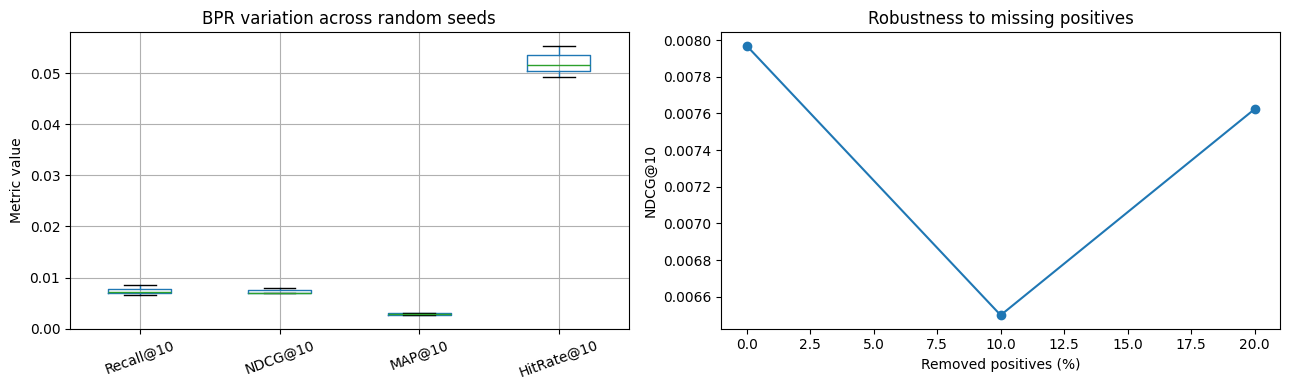

In [24]:
DROPOUT_LEVELS = [0.0, 0.10, 0.20]
dropout_rows = []

for dropout in tqdm(DROPOUT_LEVELS, desc='Interaction dropout'):
    rng = np.random.default_rng(SEED)
    if dropout == 0:
        reduced_train = train_binary
    else:
        keep = rng.random(train_binary.nnz) >= dropout
        reduced_train = train_binary.copy()
        reduced_train.data[~keep] = 0.0
        reduced_train.eliminate_zeros()

    robust_model = BayesianPersonalizedRanking(
        factors=64, learning_rate=0.05, regularization=0.01,
        iterations=20, random_state=SEED, num_threads=1,
        verify_negative_samples=True,
    )
    start = time.perf_counter()
    robust_model.fit(reduced_train, show_progress=False)
    train_seconds = time.perf_counter() - start
    recommendations = recommend_external_model(robust_model, test_users)
    metrics = ranking_metrics(
        recommendations, test_users, test_ground_truth, len(item_ids)
    )
    dropout_rows.append({
        'dropout': dropout,
        'remaining_interactions': reduced_train.nnz,
        'train_time_sec': train_seconds,
        **metrics,
    })
    if dropout > 0:
        del reduced_train
    del robust_model, recommendations
    gc.collect()

dropout_df = pd.DataFrame(dropout_rows).set_index('dropout')
baseline_ndcg = dropout_df.loc[0.0, f'NDCG@{K}']
dropout_df['NDCG_relative_change'] = dropout_df[f'NDCG@{K}'] / baseline_ndcg - 1.0
display(dropout_df.style.format('{:.6f}'))
dropout_df.to_csv(OUTPUT_DIR / 'interaction_dropout_robustness.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
seed_stability_df.boxplot(column=stability_metric_columns[:4], ax=axes[0], rot=20)
axes[0].set_title('BPR variation across random seeds')
axes[0].set_ylabel('Metric value')

axes[1].plot(dropout_df.index * 100, dropout_df[f'NDCG@{K}'], marker='o')
axes[1].set(title='Robustness to missing positives', xlabel='Removed positives (%)', ylabel=f'NDCG@{K}')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stability_and_robustness.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. Итоговые выводы

1. **BPR — лучший итоговый алгоритм на тестовой неделе:** `NDCG@10 = 0.00797`, `Recall@10 = 0.00849`, `HitRate@10 = 0.05535`. Он превосходит ALS, Popularity и все протестированные контентные варианты по основным ranking-метрикам.
2. **Мультимодальный сигнал полезен, но эффект зависит от времени и сегмента.** На валидации BPR + Content (8 измерений, вес BPR 0.75) повысил `NDCG@10` с 0.00763 до 0.00766 (примерно на 0.4%), однако на следующей тестовой неделе преимущество не сохранилось. Это может быть связано с temporal distribution shift или переобучением при выборе конфигурации на валидации.
3. **Польза контентного сигнала зависит от сегмента, но не проявляется систематически.** На тестовой неделе гибрид BPR + Content не улучшил NDCG@10 ни в одном из квартилей активности пользователей. При анализе популярности объектов улучшение наблюдалось только в сегменте Mid: NDCG@10 увеличился с 0.00562 до 0.00636. Для сегментов Tail и Head чистый BPR показал более высокое качество.
4. **Интерпретируемые метаданные слабее мультимодального эмбеддинга.** Они могут увеличить разнообразие покрытия, но не улучшают итоговое ранжирование относительно чистого BPR.
5. **Ранжирование умеренно чувствительно к случайности обучения:** коэффициент вариации NDCG по трём seed равен 7.56%, тогда как Coverage стабилен (0.47%). Эксперимент с удалением взаимодействий также показывает нестабильность BPR, поэтому единичный запуск недостаточен для сильных причинных выводов.

**Ответ на исследовательский вопрос:** на данной временной выборке коллаборативный BPR оказался наиболее надёжным общим решением. Добавление мультимодальных эмбеддингов улучшило результаты на валидации и в отдельных сегментах, однако преимущество не сохранилось на следующей тестовой неделе. Поэтому контентный сигнал следует использовать избирательно и обязательно проверять на последующих временных периодах.

**Ограничения:** датасет содержит один объединённый мультимодальный эмбеддинг, поэтому независимое сравнение текстовых и визуальных признаков невозможно. В экспериментальном каталоге также отсутствуют истинно новые объекты с нулевой историей.
